# PPO Reinforcement Learning for Flappy Bird

This notebook implements a Proximal Policy Optimization (PPO) agent to play Flappy Bird, aiming to maximize the score. The environment is based on the DeepLearningFlappyBird repository. Training is optimized for CPU and GPU usage, with periodic TensorBoard updates.

In [1]:
# Ensure cloudpickle is installed
%pip install cloudpickle
import sys
sys.path.append('./flappy_bird_repo/game')



[notice] A new release of pip is available: 23.0.1 -> 26.0.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import torch
from torch.utils.tensorboard import SummaryWriter
import numpy as np
from ppo_agent import PPOAgent, train, evaluate
import os

objc[34200]: Class SDLApplication is implemented in both /Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x17b444890) and /Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x17e3612c8). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[34200]: Class SDLAppDelegate is implemented in both /Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x17b4448e0) and /Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x17e361318). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[34200]: Class SDLTranslatorResponder is implemented in both /Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-

In [3]:
import sys
for mod in ['ppo_agent', 'vec_env']:
    if mod in sys.modules:
        del sys.modules[mod]
from ppo_agent import PPOAgent, train, evaluate


In [4]:

# ============= CHECKPOINT MANAGEMENT =============
from pathlib import Path

def get_latest_checkpoint(checkpoint_dir='checkpoints/ppo'):
    """Get the latest checkpoint file if it exists."""
    checkpoint_path = Path(checkpoint_dir)
    if not checkpoint_path.exists():
        return None
    checkpoint_files = sorted(checkpoint_path.glob('checkpoint_*.pkl'))
    return checkpoint_files[-1] if checkpoint_files else None

# ============= RESUME SWITCH =============
RESUME_TRAINING = False  # Set to False to start fresh, True to resume from last checkpoint
print(f"Resume training: {RESUME_TRAINING}")
if RESUME_TRAINING:
    latest_checkpoint = get_latest_checkpoint()
    print(f"Latest checkpoint: {latest_checkpoint}")


Resume training: False


## Initial Evaluation

Evaluate the untrained PPO agent over 1000 episodes to establish a baseline performance.

In [5]:
agent = PPOAgent()
print("Evaluating untrained agent...")
mean_score, max_score = evaluate(agent, 10)
print(f"Mean Score: {mean_score}, Max Score: {max_score}")

Using device: mps
Evaluating untrained agent...


libpng warning: iCCP: known incorrect sRGB profile
libpng warning: iCCP: known incorrect sRGB profile
libpng warning: iCCP: known incorrect sRGB profile
libpng warning: iCCP: known incorrect sRGB profile
libpng warning: iCCP: known incorrect sRGB profile
libpng warning: iCCP: known incorrect sRGB profile
libpng warning: iCCP: known incorrect sRGB profile
libpng warning: iCCP: known incorrect sRGB profile
libpng warning: iCCP: known incorrect sRGB profile
libpng warning: iCCP: known incorrect sRGB profile
libpng warning: iCCP: known incorrect sRGB profile
libpng warning: iCCP: known incorrect sRGB profile
libpng warning: iCCP: known incorrect sRGB profile
libpng warning: iCCP: known incorrect sRGB profile
libpng warning: iCCP: known incorrect sRGB profile


Mean Score: 3.5, Max Score: 3.5


## Training the Agent

Train the PPO agent for 100,000 episodes with TensorBoard logging for monitoring progress.

Training the agent...
Resume training: False

Episode: 100, Steps: 1224, AvgReward100: 3.62, MaxGameScore: 5.90, FlapRate: 0.50
Episode: 200, Steps: 2460, AvgReward100: 3.69, MaxGameScore: 5.90, FlapRate: 0.51
Episode: 300, Steps: 3702, AvgReward100: 3.71, MaxGameScore: 5.90, FlapRate: 0.50
Episode: 400, Steps: 4920, AvgReward100: 3.67, MaxGameScore: 6.00, FlapRate: 0.49
Episode: 500, Steps: 6138, AvgReward100: 3.66, MaxGameScore: 6.00, FlapRate: 0.49
Episode: 600, Steps: 7362, AvgReward100: 3.60, MaxGameScore: 8.20, FlapRate: 0.48
Episode: 700, Steps: 8580, AvgReward100: 3.66, MaxGameScore: 8.20, FlapRate: 0.47
Episode: 800, Steps: 9804, AvgReward100: 3.67, MaxGameScore: 8.20, FlapRate: 0.47
Episode: 900, Steps: 11052, AvgReward100: 3.73, MaxGameScore: 8.20, FlapRate: 0.46
Episode: 1000, Steps: 12264, AvgReward100: 3.72, MaxGameScore: 8.20, FlapRate: 0.45
  Checkpoint saved at episode 1000
  Greedy eval mean score: 2.10
Episode: 1100, Steps: 13536, AvgReward100: 3.75, MaxGameScore: 8.

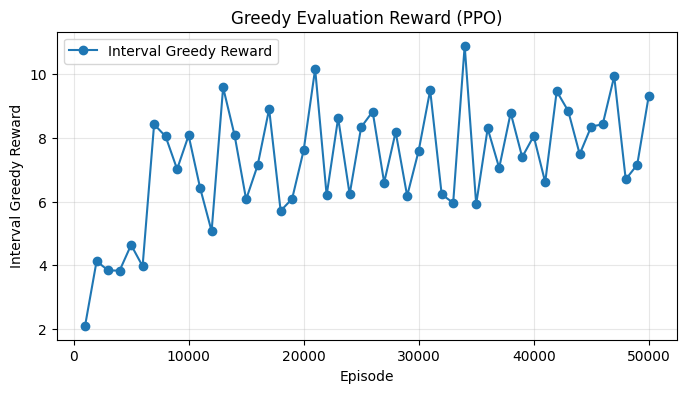

In [6]:
print("Training the agent...")
print(f"Resume training: {RESUME_TRAINING}\n")
rewards, interval_rewards = train(agent, 50000, update_timestep=2000, checkpoint_dir='checkpoints/ppo', resume_from_checkpoint=RESUME_TRAINING, checkpoint_interval=1000, num_envs=6)
print("Training completed.")

# Plot interval_rewards
import matplotlib.pyplot as plt
if interval_rewards:
    steps, interval_vals = zip(*interval_rewards)
    plt.figure(figsize=(8,4))
    plt.plot(steps, interval_vals, marker='o', label='Interval Greedy Reward')
    plt.xlabel('Episode')
    plt.ylabel('Interval Greedy Reward')
    plt.title('Greedy Evaluation Reward (PPO)')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()


## Final Evaluation

Evaluate the trained PPO agent over 1000 episodes to assess performance improvement.

In [7]:
print("Evaluating trained agent...")
mean_score, max_score = evaluate(agent, 10)
print(f"Mean Score: {mean_score}, Max Score: {max_score}")

Evaluating trained agent...
Mean Score: 10.939999999999994, Max Score: 20.000000000000025


In [8]:

# Save trained model
model_dir = Path('saved_models/ppo')
model_dir.mkdir(parents=True, exist_ok=True)

# Save policy
policy_path = model_dir / 'policy_model.pt'
torch.save(agent.policy.state_dict(), policy_path)
print(f"✓ Policy saved to {policy_path}")

# Save training metadata
import json
metadata = {
    'total_episodes_trained': len(rewards) if 'rewards' in locals() else 0,
    'mean_score': float(mean_score),
    'max_score': float(max_score),
    'hyperparameters': {
        'gamma': agent.gamma,
        'eps_clip': agent.eps_clip,
        'batch_size': agent.batch_size,
    }
}

metadata_path = model_dir / 'metadata.json'
with open(metadata_path, 'w') as f:
    json.dump(metadata, f, indent=2)
print(f"✓ Metadata saved to {metadata_path}")
print(f"\nModel saved successfully!")


✓ Policy saved to saved_models/ppo/policy_model.pt
✓ Metadata saved to saved_models/ppo/metadata.json

Model saved successfully!


## Monitoring Training with TensorBoard

To monitor the training progress, run TensorBoard in a separate terminal:

```bash
tensorboard --logdir runs
```

This will log rewards per episode.